# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import APKLOTDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 505


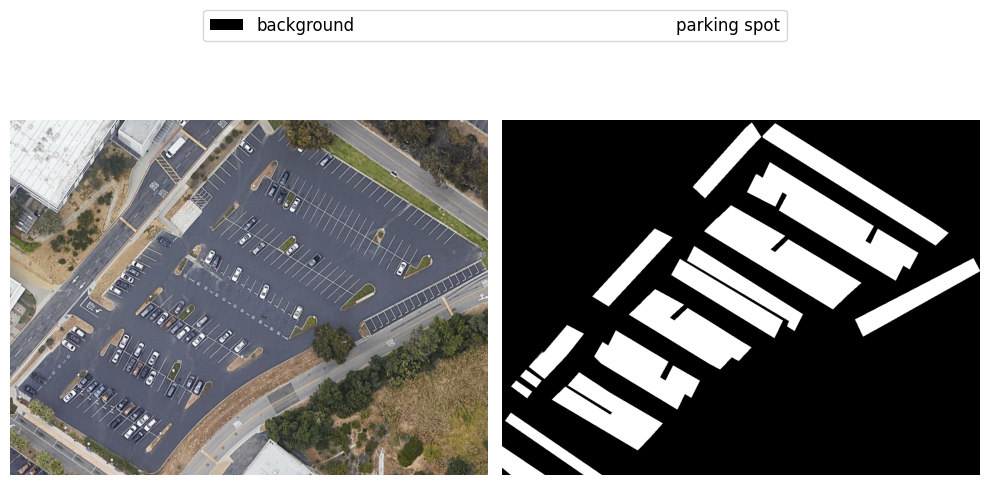

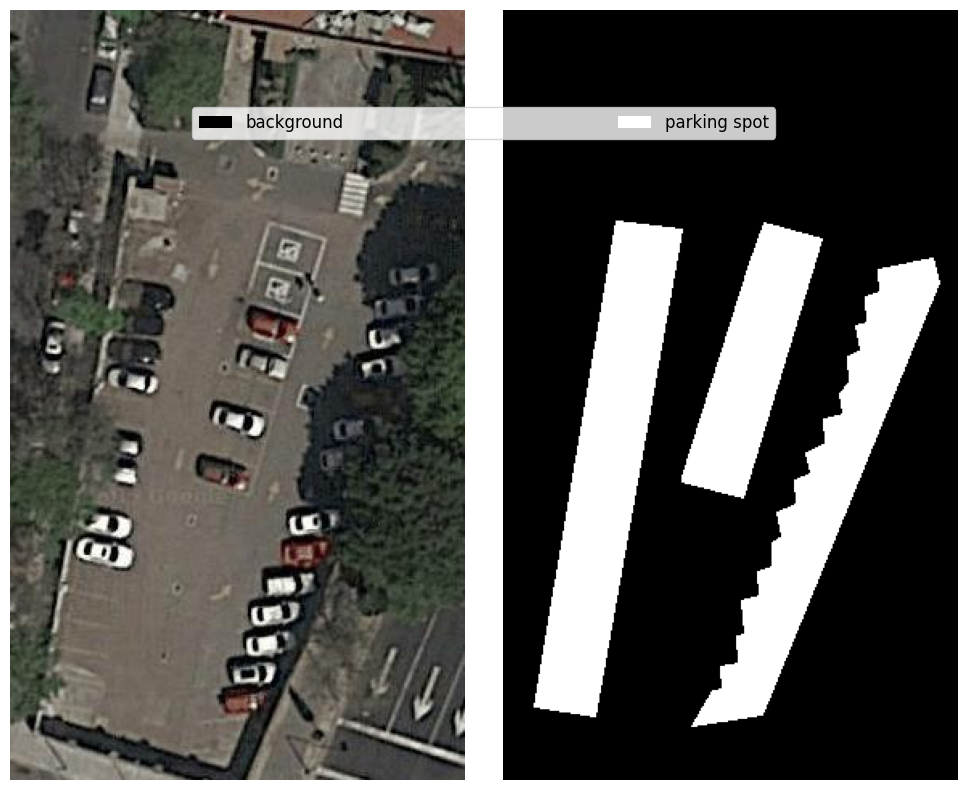

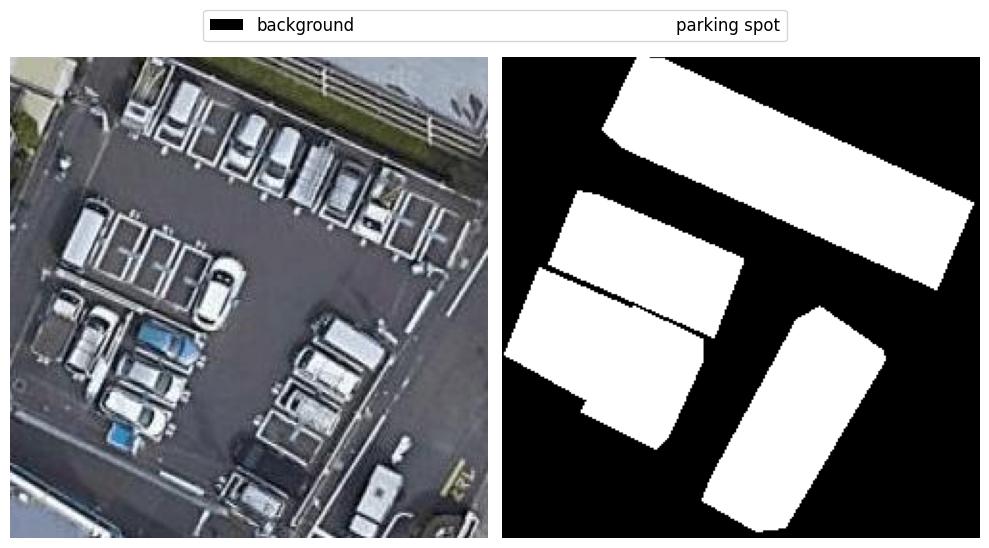

In [10]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/APKLOT"
}
dataset = APKLOTDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(250);
dataset.show_image(400);

In [11]:
dataset.data_distribution_table()

,Number of pixels
background,244469487.0
parking spot,86057972.0


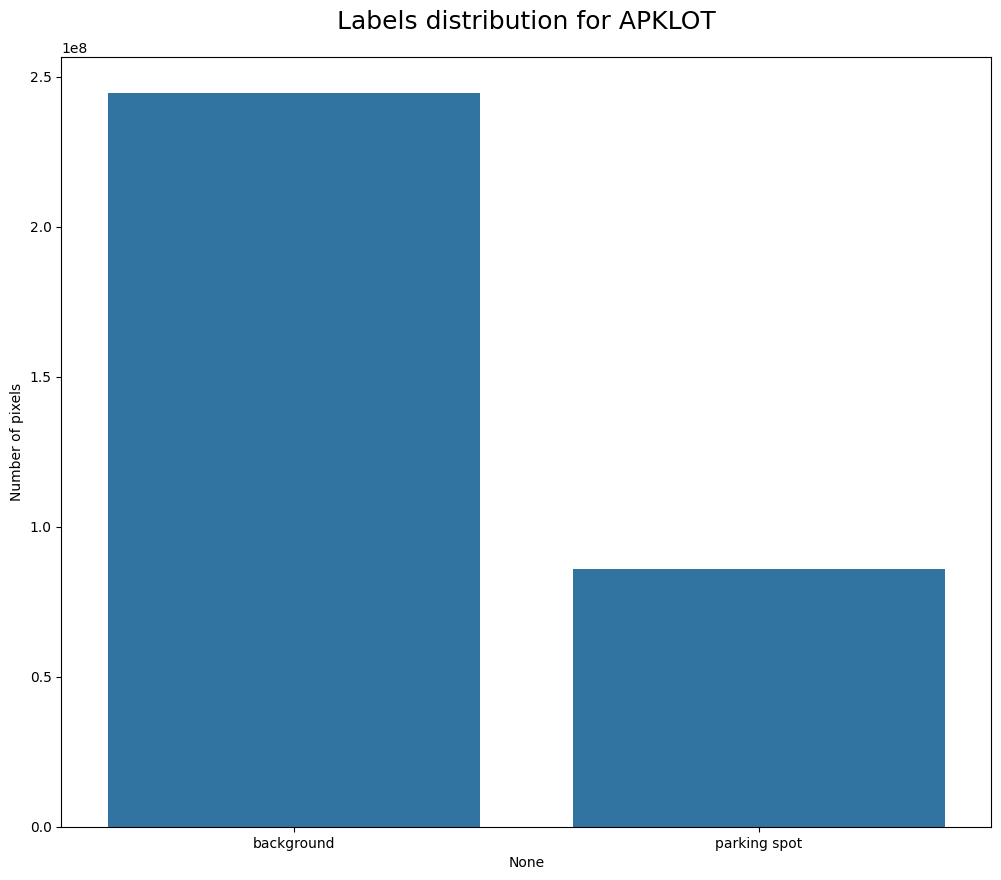

In [12]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 19,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/APKLOT/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = APKLOTDataset(train_dataset_config)
len(train_dataset)

399

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/APKLOT"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-11 07:59:14,702 INFO Starting training.
training: 100%|██████████| 21/21 [06:30<00:00, 18.58s/it]
2025-03-11 08:05:45,036 INFO epoch: 1, time: 391, loss:  0.45571
testing on train set: 100%|██████████| 21/21 [06:26<00:00, 18.43s/it]
2025-03-11 08:12:13,965 INFO IOU:0.37318289697757845, IOU mean:0.3730810132645689, IOU per Class:[0.39442246 0.35173957]
training: 100%|██████████| 21/21 [06:14<00:00, 17.85s/it]
2025-03-11 08:18:28,911 INFO epoch: 2, time: 375, loss:  0.32186
testing on train set: 100%|██████████| 21/21 [06:12<00:00, 17.75s/it]
2025-03-11 08:24:41,673 INFO IOU:0.6492620099937336, IOU mean:0.6256970430631492, IOU per Class:[0.73842062 0.51297347]
training: 100%|██████████| 21/21 [07:25<00:00, 21.22s/it]
2025-03-11 08:32:07,357 INFO epoch: 3, time: 446, loss:  0.27046
testing on train set: 100%|██████████| 21/21 [06:10<00:00, 17.64s/it]
2025-03-11 08:38:17,929 INFO IOU:0.7597718103496747, IOU mean:0.7241236690475179, IOU per Class:[0.84887932 0.59936802]
training: 10

## Evaluate the model

In [7]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/APKLOT/test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = APKLOTDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/APKLOT/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

99


2025-03-11 10:17:06,110 INFO Loading checkpoint /home/dragik/data/FAIR_EO/APKLOT/checkpoint.pth.tar
2025-03-11 10:17:06,553 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/APKLOT/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 25/25 [01:48<00:00,  4.34s/it]


[{'IOU': 0.7705928733027169,
  'IOU mean': 0.731711228885464,
  'IOU per Class': array([0.83899699, 0.62442547])}]

## Predictions

2025-03-11 10:19:02,642 INFO Loading checkpoint /home/dragik/data/FAIR_EO/APKLOT/checkpoint.pth.tar
2025-03-11 10:19:03,065 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/APKLOT/checkpoint.pth.tar at epoch 11


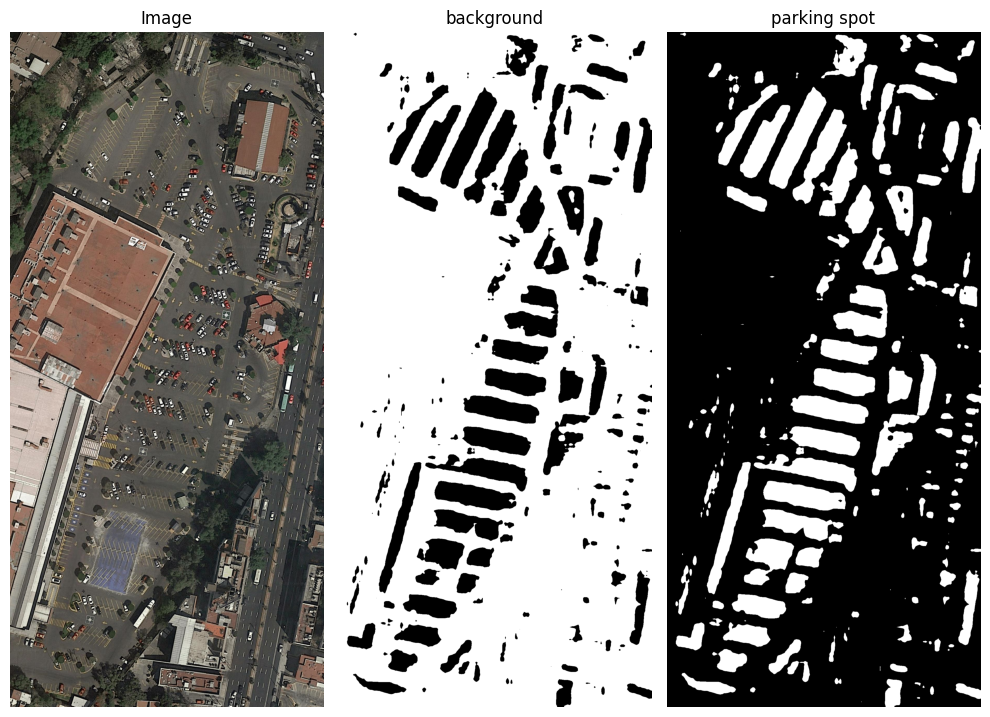

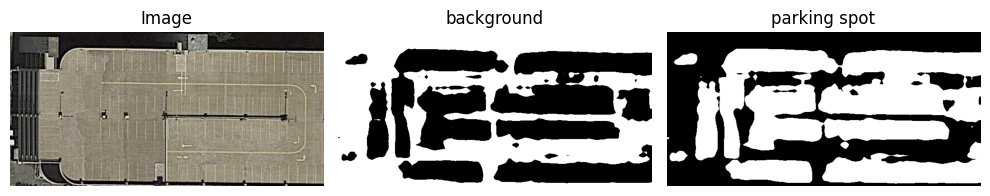

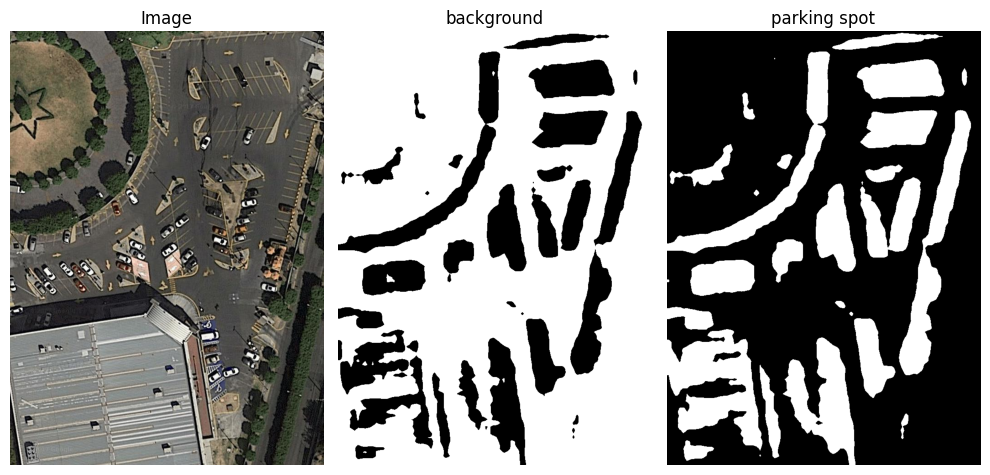

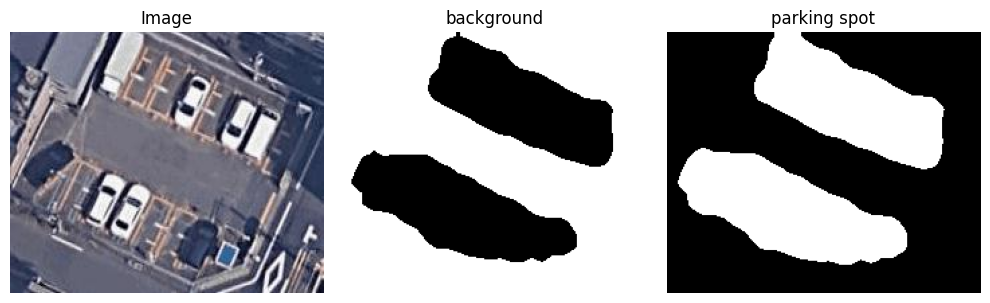

In [8]:
model_path = "/home/dragik/data/FAIR_EO/APKLOT/checkpoint.pth.tar"
labels = ["background","parking spot"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/APKLOT/test/images/27292693.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/APKLOT/test/images/43666752.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/APKLOT/test/images/54884689.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/APKLOT/test/images/208033509.jpg')
fig = model.predict_masks(image, labels, transform)